# 05 - Analyse des erreurs des modèles d'ensemble

## Women's E-Commerce Clothing Reviews

Le notebook 04 a entraîné trois modèles d'**Ensemble Learning** : **AdaBoost**, **XGBoost** et le modèle bonus
**Soft Voting (Naïve Bayes + Random Forest)**. Ce notebook ne réentraîne rien : il relit les **scores** que
ces modèles ont produits sur les 4 693 avis de test et il répond à trois questions :

1. **Quel modèle se trompe le moins**, et surtout **sur la classe minoritaire** (*non recommandé*, 17.8 % des avis) ?
   L'accuracy seule est trompeuse : un modèle qui répond toujours « recommandé » obtient déjà 82 % (*Zero-R*).
   Nous regardons donc précision, rappel et F1 **par classe**.
2. **Où se trompent-ils ?** Par note (*Rating*), par département, selon la longueur de l'avis, et quels avis
   sont difficiles pour tous les modèles.
3. **Sur quelles variables s'appuient-ils ?** Le texte (TF-IDF) ou les variables structurées ?

Les résultats sont enfin **exportés** dans `models/` pour alimenter la page *Ensemble Learning* de l'application Streamlit.

**Prérequis :** le notebook 04 doit avoir été exécuté jusqu'au bout (fichiers `ensemble_test_scores.csv`,
`adaboost_model.pkl` et `xgboost_model.pkl` dans `models/`).

## 1. Importation des bibliothèques et chemins

In [1]:
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, precision_recall_curve
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "data" / "processed").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "processed").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Le dossier data/processed est introuvable.")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "reviews_clean.csv"
MODELS_DIR = PROJECT_ROOT / "models"

REQUIRED = ["ensemble_test_scores.csv", "adaboost_model.pkl", "xgboost_model.pkl", "preprocessor.pkl"]
missing = [f for f in REQUIRED if not (MODELS_DIR / f).exists()]

if missing:
    raise FileNotFoundError(f"Fichiers manquants dans models/ : {missing}. Exécuter d'abord le notebook 04.")

print("✓ Tous les fichiers nécessaires sont présents.")

✓ Tous les fichiers nécessaires sont présents.


## 2. Jeu de test et scores des modèles

Nous reconstruisons le même jeu de test que dans les notebooks 02 à 04 (`random_state=42`, `stratify=y`),
puis nous chargeons les scores sauvegardés. Nous vérifions que **chaque ligne de score correspond bien au
bon avis**.

**Convention.** La classe **1 (recommandé)** est la classe positive.

- **Faux positif (FP)** : un avis *non recommandé* que le modèle prédit « recommandé » (un avis négatif manqué) ;
- **Faux négatif (FN)** : un avis *recommandé* que le modèle prédit « non recommandé » (une fausse alerte).

Chaque modèle fournit un **score entre 0 et 1** ; l'avis est prédit « recommandé » si le score est au moins égal au
**seuil de décision** (0.5 par défaut). Pour Linear SVC, qui ne donne pas de probabilité, le score de décision est
converti par une fonction sigmoïde : seul le seuil change d'échelle, l'ordre des avis et donc l'AUC ne changent pas.

In [2]:
df = pd.read_csv(DATA_PATH, keep_default_na=False)

TARGET_COL = "Recommended IND"
X = df.drop(columns=[TARGET_COL, "Clothing ID"]).copy()
y = df[TARGET_COL].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scores = pd.read_csv(MODELS_DIR / "ensemble_test_scores.csv", index_col="row_id")

same_rows = scores.index.equals(X_test.index) and (scores["y_true"].values == y_test.values).all()
if not same_rows:
    raise ValueError("Les scores ne correspondent pas au jeu de test reconstruit.")
print(f"✓ {len(scores)} avis de test alignés avec les scores.")

# Linear SVC : score de décision -> valeur entre 0 et 1 (sigmoïde), seuil par défaut 0.5
if scores["Linear SVC"].min() < 0 or scores["Linear SVC"].max() > 1:
    scores["Linear SVC"] = 1 / (1 + np.exp(-scores["Linear SVC"]))

MODEL_NAMES = [m for m in ["AdaBoost", "XGBoost", "Soft Voting (NB + RF)", "Random Forest", "Linear SVC"]
               if m in scores.columns]
ENSEMBLES = [m for m in ["AdaBoost", "XGBoost", "Soft Voting (NB + RF)"] if m in MODEL_NAMES]
y_true = scores["y_true"].values

print("Modèles analysés :", MODEL_NAMES)
print("Classe minoritaire (non recommandé) :", f"{(y_true == 0).mean():.1%} des avis de test")

✓ 4693 avis de test alignés avec les scores.
Modèles analysés : ['AdaBoost', 'XGBoost', 'Soft Voting (NB + RF)', 'Random Forest', 'Linear SVC']
Classe minoritaire (non recommandé) : 17.8% des avis de test


## 3. Métriques par classe

C'est le point soulevé par l'évaluation : sur des données déséquilibrées, il faut regarder la **classe
minoritaire** séparément. Pour chaque modèle (seuil 0.5) :

- **Précision classe 0** : parmi les avis annoncés « non recommandé », quelle part l'est vraiment ?
- **Rappel classe 0** : parmi les vrais avis « non recommandé », quelle part est détectée ?
- **F1 classe 0** : compromis entre les deux (indicateur principal pour la classe minoritaire) ;
- **AP classe 0** : *average precision*, résumé de la courbe précision-rappel de la classe minoritaire,
  indépendant du seuil.

In [3]:
def class_metrics(y_true, score, threshold=0.5):
    """Métriques par classe pour un seuil de décision donné (classe 1 = positive)."""
    pred = (np.asarray(score) >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": (tn + tp) / len(y_true),
        "Precision_0": p[0], "Recall_0": r[0], "F1_0": f[0],
        "Precision_1": p[1], "Recall_1": r[1], "F1_1": f[1],
        "Macro F1": (f[0] + f[1]) / 2,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


rows = []
for name in MODEL_NAMES:
    row = {"Model": name, **class_metrics(y_true, scores[name].values)}
    row["ROC-AUC"] = roc_auc_score(y_true, scores[name])
    row["AP_0"] = average_precision_score(1 - y_true, 1 - scores[name])
    rows.append(row)

metrics_df = pd.DataFrame(rows).set_index("Model")
metrics_df = metrics_df[["Accuracy", "ROC-AUC", "Precision_0", "Recall_0", "F1_0", "AP_0",
                         "Precision_1", "Recall_1", "F1_1", "Macro F1", "TN", "FP", "FN", "TP"]]

print("Métriques au seuil 0.5, triées par F1 de la classe minoritaire :\n")
print(metrics_df.sort_values("F1_0", ascending=False).round(3).to_string())

Métriques au seuil 0.5, triées par F1 de la classe minoritaire :

                       Accuracy  ROC-AUC  Precision_0  Recall_0   F1_0   AP_0  Precision_1  Recall_1   F1_1  Macro F1   TN   FP   FN    TP
Model                                                                                                                                     
AdaBoost                  0.934    0.974        0.781     0.874  0.825  0.900        0.972     0.947  0.959     0.892  729  105  205  3654
Linear SVC                0.938    0.977        0.830     0.818  0.824  0.916        0.961     0.964  0.962     0.893  682  152  140  3719
XGBoost                   0.934    0.973        0.799     0.839  0.819  0.901        0.965     0.954  0.960     0.889  700  134  176  3683
Soft Voting (NB + RF)     0.936    0.974        0.849     0.779  0.812  0.895        0.953     0.970  0.961     0.887  650  184  116  3743
Random Forest             0.935    0.972        0.857     0.759  0.805  0.890        0.949     0.973

## 4. Matrices de confusion

Chaque matrice est normalisée par ligne : la case en bas à gauche, par exemple, indique la part des avis
*non recommandés* que le modèle a bien reconnus (c'est le rappel de la classe 0). Les effectifs sont indiqués
entre parenthèses.

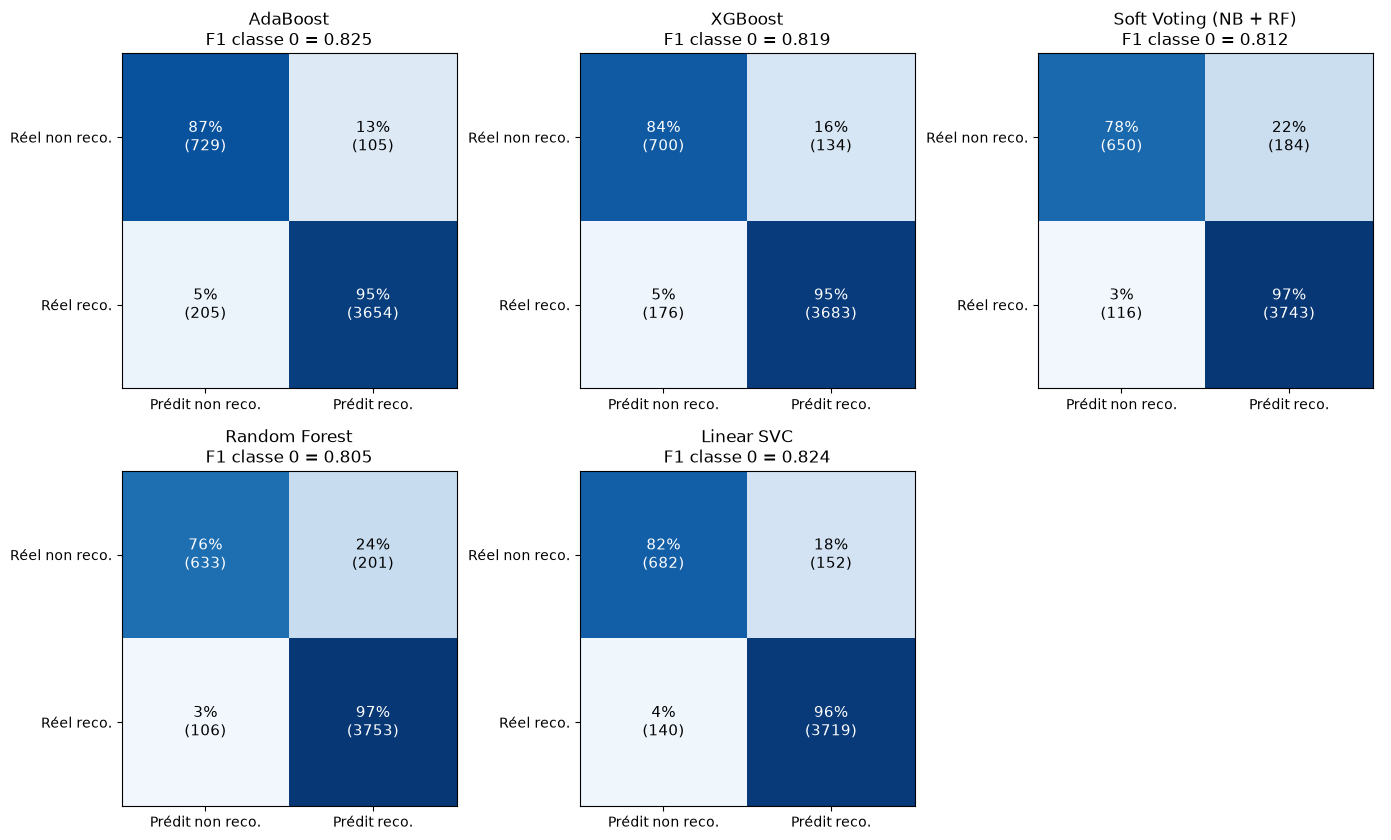

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
axes = axes.ravel()

for ax, name in zip(axes, MODEL_NAMES):
    pred = (scores[name].values >= 0.5).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm_norm[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Prédit non reco.", "Prédit reco."])
    ax.set_yticklabels(["Réel non reco.", "Réel reco."])
    ax.set_title(f"{name}\nF1 classe 0 = {metrics_df.loc[name, 'F1_0']:.3f}")
    ax.grid(False)

for ax in axes[len(MODEL_NAMES):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Courbes ROC et précision-rappel de la classe minoritaire

- La **courbe ROC** compare les modèles quel que soit le seuil : plus elle est proche du coin supérieur gauche,
  mieux c'est (AUC proche de 1).
- La **courbe précision-rappel de la classe 0** est plus parlante ici, car elle ne tient pas compte des
  nombreux avis positifs faciles à classer : elle montre le prix à payer en précision pour détecter plus
  d'avis négatifs.

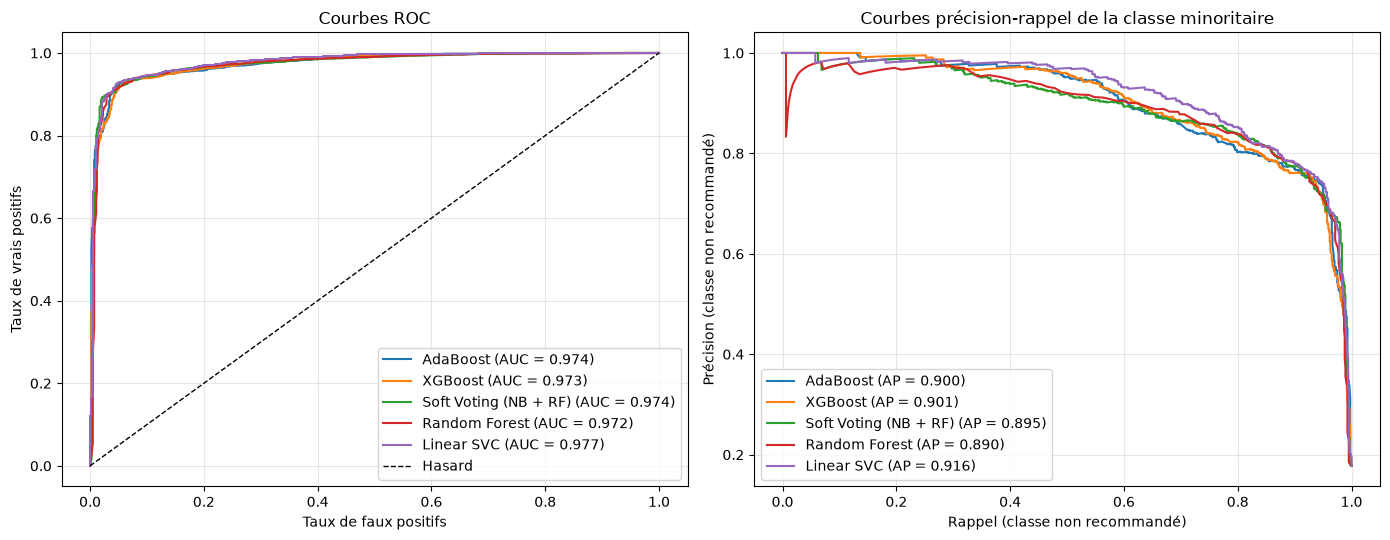

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_true, scores[name])
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {metrics_df.loc[name, 'ROC-AUC']:.3f})")

    prec, rec, _ = precision_recall_curve(1 - y_true, 1 - scores[name])
    ax2.plot(rec, prec, label=f"{name} (AP = {metrics_df.loc[name, 'AP_0']:.3f})")

ax1.plot([0, 1], [0, 1], "k--", linewidth=1, label="Hasard")
ax1.set_xlabel("Taux de faux positifs"); ax1.set_ylabel("Taux de vrais positifs")
ax1.set_title("Courbes ROC"); ax1.legend(loc="lower right")

ax2.set_xlabel("Rappel (classe non recommandé)"); ax2.set_ylabel("Précision (classe non recommandé)")
ax2.set_title("Courbes précision-rappel de la classe minoritaire"); ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

## 6. Effet du seuil de décision sur la classe minoritaire

Par défaut, un avis est prédit « recommandé » dès que son score atteint 0.5. **Relever le seuil** rend le modèle
plus méfiant : il détecte plus d'avis négatifs (le rappel de la classe 0 monte), mais il se trompe plus souvent
sur les avis positifs (la précision de la classe 0 baisse).

**Précaution :** le seuil optimal ci-dessous est choisi **sur le jeu de test**, donc il est légèrement
optimiste. Il sert à comprendre le compromis, pas à annoncer une performance finale : une vraie sélection
de seuil demanderait un jeu de validation séparé.

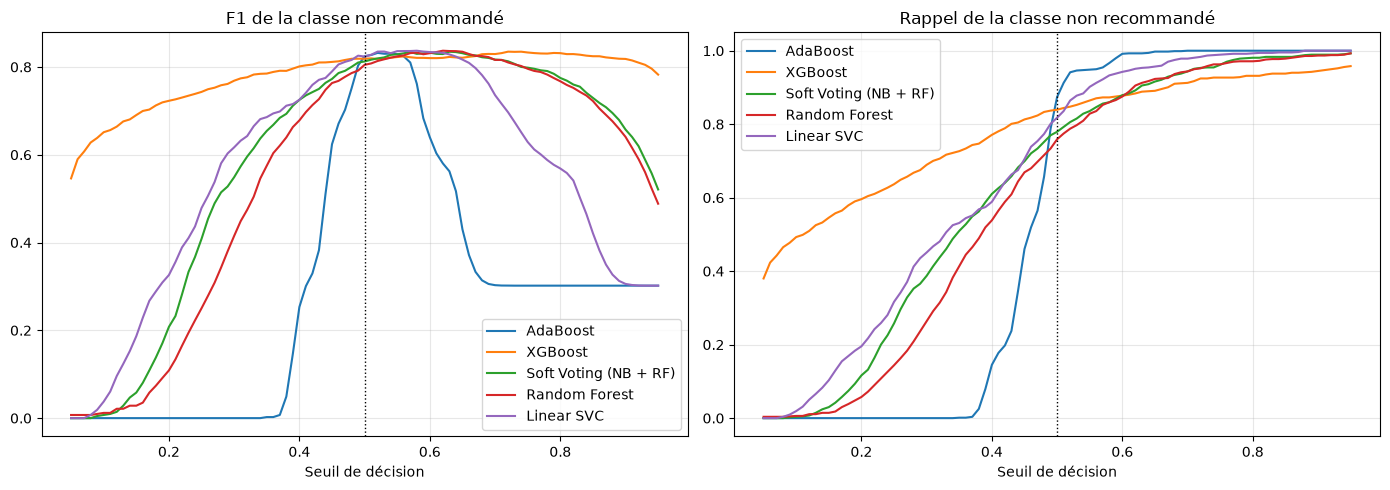

                       F1_0 à 0.5  Meilleur seuil  F1_0 au meilleur seuil  Rappel_0 au meilleur seuil  Précision_0 au meilleur seuil
Model                                                                                                                               
AdaBoost                    0.825            0.52                   0.832                       0.941                          0.745
Linear SVC                  0.824            0.58                   0.837                       0.933                          0.759
Random Forest               0.805            0.62                   0.837                       0.905                          0.778
Soft Voting (NB + RF)       0.812            0.63                   0.835                       0.905                          0.774
XGBoost                     0.819            0.72                   0.835                       0.924                          0.761


In [6]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

sweep = pd.DataFrame([
    {"Model": name, "Threshold": t, **{k: v for k, v in class_metrics(y_true, scores[name].values, t).items()
                                       if k in ("Precision_0", "Recall_0", "F1_0")}}
    for name in MODEL_NAMES for t in thresholds
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name in MODEL_NAMES:
    s = sweep[sweep["Model"] == name]
    ax1.plot(s["Threshold"], s["F1_0"], label=name)
    ax2.plot(s["Threshold"], s["Recall_0"], label=name)

for ax, title in [(ax1, "F1 de la classe non recommandé"), (ax2, "Rappel de la classe non recommandé")]:
    ax.axvline(0.5, color="k", linestyle=":", linewidth=1)
    ax.set_xlabel("Seuil de décision"); ax.set_title(title); ax.legend()

plt.tight_layout()
plt.show()

best_rows = sweep.loc[sweep.groupby("Model")["F1_0"].idxmax()].set_index("Model")
summary_thr = pd.DataFrame({
    "F1_0 à 0.5": metrics_df["F1_0"],
    "Meilleur seuil": best_rows["Threshold"],
    "F1_0 au meilleur seuil": best_rows["F1_0"],
    "Rappel_0 au meilleur seuil": best_rows["Recall_0"],
    "Précision_0 au meilleur seuil": best_rows["Precision_0"],
}).round(3)
print(summary_thr.to_string())

## 7. Où les modèles se trompent-ils ?

Nous marquons chaque prédiction comme **erreur** ou non (seuil 0.5), puis nous comparons les taux d'erreur selon
la note de l'avis, le département et la longueur du texte. Un taux élevé dans un groupe indique un type d'avis
que le modèle comprend mal.

Taux d'erreur (%) selon la note (Rating) :

        Nb avis  AdaBoost  XGBoost  Soft Voting (NB + RF)  Random Forest  Linear SVC
Rating                                                                              
1           156       1.9      1.9                    8.3            3.2         1.9
2           297       4.7      4.4                    9.1            6.4         4.4
3           614      40.6     40.7                   34.4           38.4        37.8
4           995       3.8      3.8                    4.3            4.0         3.8
5          2631       0.2      0.2                    0.2            0.3         0.2

Taux d'erreur (%) selon le département :

                 Nb avis  AdaBoost  XGBoost  Soft Voting (NB + RF)  Random Forest  Linear SVC
Department Name                                                                              
Bottoms              778       5.4      5.9                    5.9            6.2         5.0
Dresses             1243       7.8  

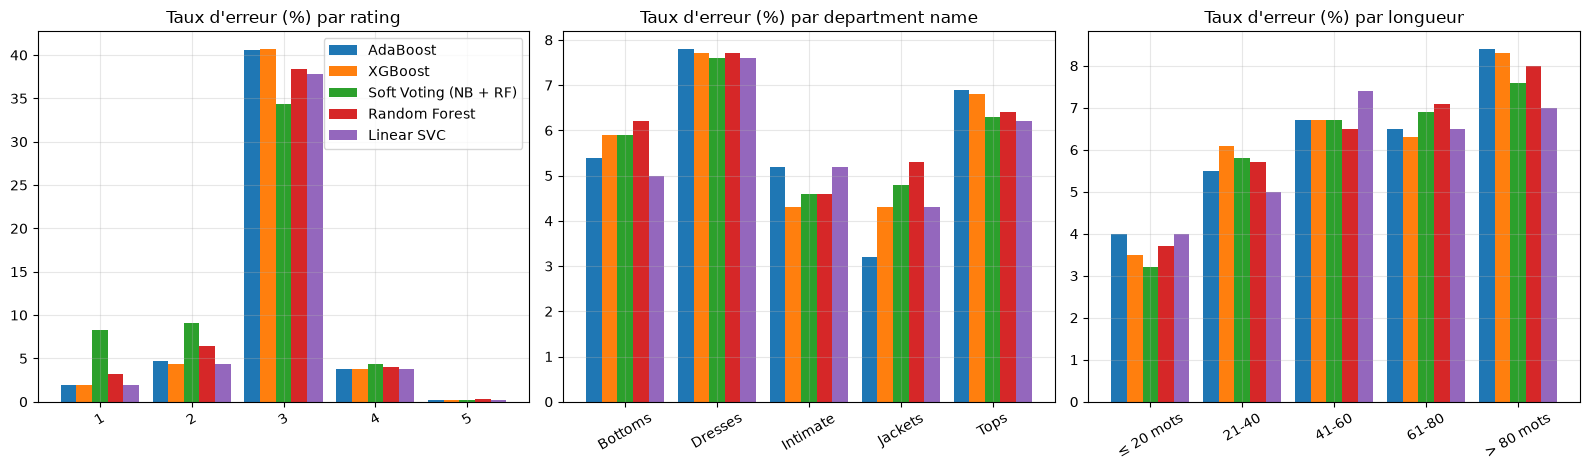

In [7]:
errors = pd.DataFrame(
    {name: (scores[name].values >= 0.5).astype(int) != y_true for name in MODEL_NAMES},
    index=scores.index
)

meta = X_test.copy()
meta["n_words"] = meta["Review Text"].str.split().str.len()
meta["Longueur"] = pd.cut(meta["n_words"], [-1, 20, 40, 60, 80, 10000],
                          labels=["≤ 20 mots", "21-40", "41-60", "61-80", "> 80 mots"])


def error_rate_by(column):
    table = (errors.groupby(meta[column]).mean() * 100).round(1)
    table.insert(0, "Nb avis", meta.groupby(column).size())
    return table


print("Taux d'erreur (%) selon la note (Rating) :\n")
print(error_rate_by("Rating").to_string())
print("\nTaux d'erreur (%) selon le département :\n")
print(error_rate_by("Department Name").to_string())
print("\nTaux d'erreur (%) selon la longueur de l'avis :\n")
print(error_rate_by("Longueur").to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, ["Rating", "Department Name", "Longueur"]):
    table = error_rate_by(col)
    table = table[table["Nb avis"] >= 30].drop(columns="Nb avis")
    table.plot(kind="bar", ax=ax, width=0.85, legend=(col == "Rating"))
    ax.set_title(f"Taux d'erreur (%) par {col.lower()}")
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 8. Les erreurs sont-elles communes à tous les modèles ?

Si tous les modèles se trompent sur les mêmes avis, ceux-ci sont intrinsèquement ambigus (par exemple un avis
chaleureux accompagné d'un « non recommandé »). Si les erreurs diffèrent, combiner les modèles peut aider.
Nous comparons aussi le **meilleur modèle d'ensemble** (selon le F1 de la classe 0) au **champion du notebook 03**,
Linear SVC.

In [8]:
n_errors = errors.sum(axis=1)

agreement = n_errors.value_counts().sort_index()
agreement.index = [f"{k} modèle(s) sur {len(MODEL_NAMES)} se trompent" for k in agreement.index]
print(agreement.rename("Nb avis").to_frame().to_string())

hard = n_errors == len(MODEL_NAMES)
print(f"\nAvis ratés par tous les modèles : {hard.sum()} ({hard.mean():.1%} du test)")
print("Répartition de ces avis difficiles par classe réelle :")
print(pd.Series(y_true[hard.values]).map({0: "non recommandé", 1: "recommandé"}).value_counts().to_string())

focus = metrics_df.loc[ENSEMBLES, "F1_0"].idxmax()
print(f"\nMeilleur modèle d'ensemble (F1 classe 0) : {focus}")

if "Linear SVC" in errors.columns:
    fixed = int((errors["Linear SVC"] & ~errors[focus]).sum())
    broken = int((~errors["Linear SVC"] & errors[focus]).sum())
    print(f"Erreurs de Linear SVC corrigées par {focus} : {fixed}")
    print(f"Nouvelles erreurs introduites par {focus} : {broken}")
    print(f"Bilan net : {fixed - broken:+d} avis")

                               Nb avis
0 modèle(s) sur 5 se trompent     4162
1 modèle(s) sur 5 se trompent      148
2 modèle(s) sur 5 se trompent      101
3 modèle(s) sur 5 se trompent       85
4 modèle(s) sur 5 se trompent       71
5 modèle(s) sur 5 se trompent      126

Avis ratés par tous les modèles : 126 (2.7% du test)
Répartition de ces avis difficiles par classe réelle :
non recommandé    64
recommandé        62

Meilleur modèle d'ensemble (F1 classe 0) : AdaBoost
Erreurs de Linear SVC corrigées par AdaBoost : 79
Nouvelles erreurs introduites par AdaBoost : 97
Bilan net : -18 avis


## 9. Exemples d'avis mal classés avec une forte confiance

Les erreurs les plus instructives sont celles où le modèle est **très sûr de lui** et pourtant se trompe.
Nous affichons, pour le meilleur modèle d'ensemble, les faux positifs (avis négatifs manqués) et les faux négatifs
(fausses alertes) les plus confiants.

In [9]:
def show_examples(model, kind, n=5, width=230):
    score = scores[model].values
    pred = (score >= 0.5).astype(int)

    if kind == "FP":
        mask = (y_true == 0) & (pred == 1)
        confidence = score
        title = "Faux positifs : avis NON recommandés prédits « recommandé »"
    else:
        mask = (y_true == 1) & (pred == 0)
        confidence = 1 - score
        title = "Faux négatifs : avis recommandés prédits « non recommandé »"

    order = np.argsort(-np.where(mask, confidence, -1))[:n]
    print(f"=== {title} ({mask.sum()} au total) ===")
    for pos in order:
        idx = scores.index[pos]
        text = " ".join(str(meta.loc[idx, "Review Text"]).split())
        print(f"- note {meta.loc[idx, 'Rating']} | {meta.loc[idx, 'Department Name']} | "
              f"confiance {confidence[pos]:.2f}\n  « {text[:width]}{'…' if len(text) > width else ''} »")
    print()


show_examples(focus, "FP")
show_examples(focus, "FN")

=== Faux positifs : avis NON recommandés prédits « recommandé » (105 au total) ===
- note 5 | Dresses | confiance 0.70
  « I also have this dress in 3/4 sleeve, tegan tunic. i love this dress. it can be dressed up or down. »
- note 5 | Tops | confiance 0.68
  « This shirt is like the best worn in flannel with a little feminine flair! super soft and great length. »
- note 5 | Dresses | confiance 0.64
  «  »
- note 5 | Dresses | confiance 0.64
  « This jumpsuit runs large so i sized down perfectly one full size down. i have a size b chest and was very comfortable with no bra, as the built in cups gave me the perfect coverage. it looked like a dress standing, but had such a … »
- note 5 | Tops | confiance 0.64
  « I've wondered abt this swtr but hesitated to order being it has dolman sleeves. decided to wait for it to come in at the local store. yesterday i spotted it in the store & tried on the orange, labeled 'red' online. i was really lo… »

=== Faux négatifs : avis recommandés prédits

## 10. Sur quelles variables s'appuient AdaBoost et XGBoost ?

Les deux modèles fournissent une **importance** pour chacune des 13 035 variables (la somme vaut 1).
Nous regardons d'abord les variables individuelles les plus importantes, puis nous regroupons l'importance par
**bloc** : variables numériques, catégorielles, TF-IDF du titre et TF-IDF de l'avis. Cela montre si ces modèles
s'appuient surtout sur le texte ou sur les variables structurées (la note `Rating` en particulier).

Part de l'importance par bloc de variables :

                                                     XGBoost  AdaBoost
Bloc                                                                  
Catégorielles (division, département, classe)       1.000000       0.6
Numériques (Age, Rating, Positive Feedback Count)  27.600000      30.4
Avis (TF-IDF)                                      61.700001      58.5
Titre (TF-IDF)                                      9.700000      10.5


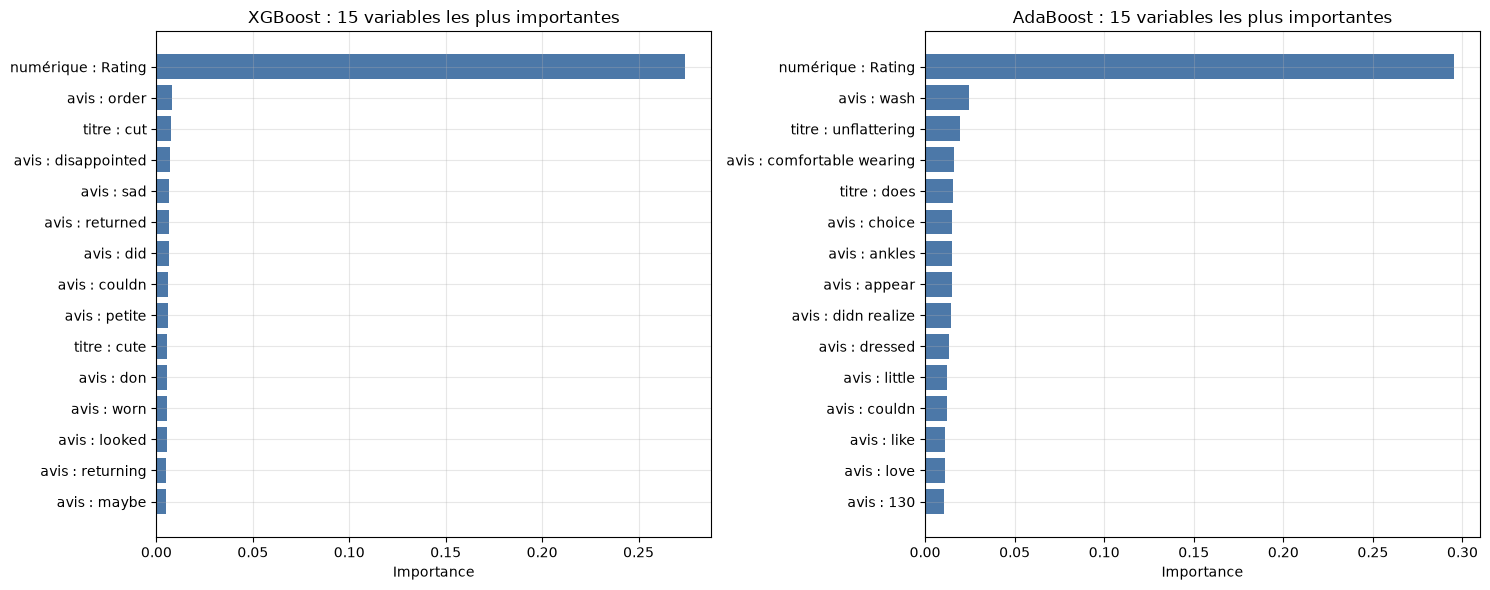

In [10]:
preprocessor = joblib.load(MODELS_DIR / "preprocessor.pkl")
feature_names = preprocessor.get_feature_names_out()

BLOCKS = {
    "num": "Numériques (Age, Rating, Positive Feedback Count)",
    "cat": "Catégorielles (division, département, classe)",
    "title_tfidf": "Titre (TF-IDF)",
    "review_tfidf": "Avis (TF-IDF)",
}
PREFIXES = {"num": "numérique", "cat": "catégorie", "title_tfidf": "titre", "review_tfidf": "avis"}


def pretty(name):
    prefix, _, feature = name.partition("__")
    return f"{PREFIXES[prefix]} : {feature}"


importances = {
    "XGBoost": joblib.load(MODELS_DIR / "xgboost_model.pkl").feature_importances_,
    "AdaBoost": joblib.load(MODELS_DIR / "adaboost_model.pkl").feature_importances_,
}

for model_name, values in importances.items():
    if len(values) != len(feature_names):
        raise ValueError(f"{model_name} : {len(values)} importances pour {len(feature_names)} variables.")

top_tables, block_tables = [], []
for model_name, values in importances.items():
    imp = pd.DataFrame({
        "Model": model_name,
        "Block": [PREFIXES[n.split("__")[0]] for n in feature_names],
        "Feature": [pretty(n) for n in feature_names],
        "Importance": values / values.sum(),
    })
    top_tables.append(imp.sort_values("Importance", ascending=False).head(20).reset_index(drop=True))

    share = (imp.assign(prefix=[n.split("__")[0] for n in feature_names])
                .groupby("prefix")["Importance"].sum().rename(model_name))
    block_tables.append(share)

top_features = pd.concat(top_tables, ignore_index=True)
block_share = pd.concat(block_tables, axis=1).rename(index=BLOCKS)
block_share.index.name = "Bloc"

print("Part de l'importance par bloc de variables :\n")
print((block_share * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, model_name in zip(axes, importances):
    t = top_features[top_features["Model"] == model_name].head(15).iloc[::-1]
    ax.barh(t["Feature"], t["Importance"], color="#4c78a8")
    ax.set_title(f"{model_name} : 15 variables les plus importantes")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 11. Export pour l'application Streamlit

L'application ne recharge ni les modèles ni les matrices (trop lourds) : elle lit trois petits fichiers,
produits ici dans `models/` :

- `ensemble_class_metrics.csv` : les métriques par classe de chaque modèle ;
- `error_analysis.csv` : une ligne par avis de test, avec le score de chaque modèle et des informations sur
  l'avis (note, département, longueur, texte). L'application en tire des matrices de confusion et des courbes
  ROC **interactives**, avec un curseur pour le seuil de décision ;
- `ensemble_feature_importance.csv` : les 20 variables les plus importantes de chaque modèle, et
- `ensemble_block_importance.csv` : l'importance par bloc de variables.

In [11]:
metrics_df.round(4).to_csv(MODELS_DIR / "ensemble_class_metrics.csv", index_label="Model")

export = pd.DataFrame({"row_id": scores.index, "y_true": y_true})
for name in MODEL_NAMES:
    export[name] = scores[name].round(4).values
for col in ["Rating", "Department Name", "Class Name", "Age", "n_words", "Title", "Review Text"]:
    export[col] = meta.loc[scores.index, col].values
export.to_csv(MODELS_DIR / "error_analysis.csv", index=False)

top_features.round(6).to_csv(MODELS_DIR / "ensemble_feature_importance.csv", index=False)
block_share.round(6).to_csv(MODELS_DIR / "ensemble_block_importance.csv", index_label="Bloc")

print("✓ Fichiers exportés dans models/ :")
for f in ["ensemble_class_metrics.csv", "error_analysis.csv",
          "ensemble_feature_importance.csv", "ensemble_block_importance.csv"]:
    print(f"  - {f} ({(MODELS_DIR / f).stat().st_size / 1024:.0f} Ko)")

✓ Fichiers exportés dans models/ :
  - ensemble_class_metrics.csv (1 Ko)
  - error_analysis.csv (1746 Ko)
  - ensemble_feature_importance.csv (2 Ko)
  - ensemble_block_importance.csv (0 Ko)


## 12. Synthèse automatique

Ce dernier bloc résume les résultats pour la rédaction du rapport.

In [12]:
best_f1_0 = metrics_df["F1_0"].idxmax()
best_auc = metrics_df["ROC-AUC"].idxmax()
best_ens = metrics_df.loc[ENSEMBLES, "F1_0"].idxmax()

print(f"- Meilleur F1 sur la classe minoritaire : {best_f1_0} ({metrics_df.loc[best_f1_0, 'F1_0']:.3f})")
print(f"- Meilleur ROC-AUC : {best_auc} ({metrics_df.loc[best_auc, 'ROC-AUC']:.4f})")
print(f"- Meilleur modèle d'ensemble parmi les nouveaux : {best_ens} "
      f"(F1 classe 0 = {metrics_df.loc[best_ens, 'F1_0']:.3f}, rappel classe 0 = {metrics_df.loc[best_ens, 'Recall_0']:.3f})")

if "Linear SVC" in metrics_df.index:
    gap = metrics_df.loc[best_ens, "F1_0"] - metrics_df.loc["Linear SVC", "F1_0"]
    print(f"- Écart de F1 classe 0 entre {best_ens} et le champion Linear SVC : {gap:+.3f}")

print("\nBlocs de variables les plus utilisés :")
for model_name in block_share.columns:
    top_block = block_share[model_name].idxmax()
    print(f"- {model_name} : {top_block} ({block_share.loc[top_block, model_name]:.0%} de l'importance)")

- Meilleur F1 sur la classe minoritaire : AdaBoost (0.825)
- Meilleur ROC-AUC : Linear SVC (0.9775)
- Meilleur modèle d'ensemble parmi les nouveaux : AdaBoost (F1 classe 0 = 0.825, rappel classe 0 = 0.874)
- Écart de F1 classe 0 entre AdaBoost et le champion Linear SVC : +0.001

Blocs de variables les plus utilisés :
- XGBoost : Avis (TF-IDF) (62% de l'importance)
- AdaBoost : Avis (TF-IDF) (59% de l'importance)
